# Análisis Exploratorio Bivariado: Factores Asociados a la Supervivencia en el Titanic

**Universidad:** Universidad Andrés Bello (UNAB)  
**Programa:** Magíster en Ciencia de Datos e Inteligencia Artificial  
**Asignatura:** MCDI503 - Exploración Inteligente para la Ciencia de Datos  
**Evaluación:** Sumativa 1 - Fase 1 (Bloque de Análisis Bivariado)  
**Integrantes:** Hernán Saavedra · Lenin Morales Salas · Rodrigo Gómez  

---

## 1. Contexto y propósito del módulo

A partir del diagnóstico inicial realizado sobre el dataset `titanic` (891 registros y 15 variables, con una tasa global de supervivencia del **38,38 %**), este notebook desarrolla el **análisis exploratorio bivariado y multivariado básico**. El objetivo es evaluar cómo varía la supervivencia (`survived`) en función de variables demográficas, socioeconómicas y familiares, así como analizar la relación entre la tarifa pagada (`fare`) y la clase del boleto (`class`).

### Criterios de reproducibilidad y trazabilidad
- Se conserva intacto el DataFrame original (`titanic_raw`) y se trabaja sobre una copia explícita (`titanic_eda`) para las variables derivadas (`family_size`, `age_group`).
- Cada bloque sigue la secuencia metodológica del curso: **Pregunta exploratoria → Acción / Código → Resultados cuantitativos y gráficos → Interpretación y decisión exploratoria**.
- El alcance es estrictamente descriptivo y exploratorio (no establece causalidad ni contempla pruebas de hipótesis o modelos predictivos en esta fase).

## 2. Configuración del entorno y preparación reproducible de datos

**Objetivo:** Cargar las bibliotecas necesarias, registrar sus versiones, leer el dataset de forma reproducible y construir las variables derivadas requeridas para el análisis bivariado (`family_size` y tramos etarios `age_group`).

**Decisiones metodológicas aplicadas (continuidad del diagnóstico inicial):**
- **D1 (Trazabilidad):** Se mantiene `titanic_raw` sin alterar y se crean variables derivadas sobre `titanic_eda`.
- **D2 (Variable derivada familiar):** Se define `family_size = sibsp + parch + 1` para capturar el tamaño total del núcleo familiar a bordo (incluyendo al propio pasajero).
- **D3 (Tratamiento de `age`):** Dado que `age` presenta 177 valores faltantes (19,87 %), no se imputa artificialmente en esta fase; los análisis que involucren edad operarán sobre los 714 registros válidos, dejando explícito el tamaño muestral efectivo ($n = 714$).

In [1]:
# ==================================================
# CONFIGURACIÓN DEL ENTORNO Y PREPARACIÓN DE DATOS
# ==================================================

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual global
sns.set_theme(style="whitegrid", context="notebook", palette="Set2")
plt.rcParams["figure.dpi"] = 110

print(f"Python: {sys.version.split()[0]} | Pandas: {pd.__version__} | NumPy: {np.__version__} | Seaborn: {sns.__version__}")

# Carga reproducible: busca archivo local en datos/titanic.csv o directorio actual, con respaldo en Seaborn
ruta_actual = Path.cwd().resolve()
posibles_rutas = [
    ruta_actual / "datos" / "titanic.csv",
    ruta_actual.parent / "datos" / "titanic.csv",
    ruta_actual / "titanic.csv"
]

ruta_encontrada = next((r for r in posibles_rutas if r.exists()), None)

if ruta_encontrada is not None:
    titanic_raw = pd.read_csv(ruta_encontrada)
    print(f"Dataset cargado desde archivo local: {ruta_encontrada}")
else:
    titanic_raw = sns.load_dataset("titanic")
    print("Dataset cargado desde repositorio Seaborn (sns.load_dataset).")

# Copia de trabajo para EDA
titanic_eda = titanic_raw.copy()

# Orden lógico para la variable categórica 'class'
orden_clases = ["First", "Second", "Third"]
titanic_eda["class"] = pd.Categorical(titanic_eda["class"], categories=orden_clases, ordered=True)

# Variable derivada 1: Tamaño del grupo familiar a bordo
titanic_eda["family_size"] = titanic_eda["sibsp"] + titanic_eda["parch"] + 1

# Variable derivada 2: Tramos de tamaño familiar para lectura agrupada
titanic_eda["family_group"] = pd.cut(
    titanic_eda["family_size"],
    bins=[0, 1, 4, 15],
    labels=["Solo (1)", "Familia pequeña (2-4)", "Familia numerosa (5+)"]
)

# Variable derivada 3: Tramos etarios (conservando NaN donde no hay dato)
titanic_eda["age_group"] = pd.cut(
    titanic_eda["age"],
    bins=[0, 12, 18, 35, 60, 85],
    labels=["Niños (0-12)", "Adolescentes (13-18)", "Adultos jóvenes (19-35)", "Adultos (36-60)", "Adultos mayores (60+)"]
)

print(f"Dimensiones titanic_raw: {titanic_raw.shape} | Dimensiones titanic_eda: {titanic_eda.shape}")
display(titanic_eda[["survived", "sex", "class", "age", "age_group", "fare", "family_size", "family_group"]].head())

Python: 3.13.15 | Pandas: 3.1.1 | NumPy: 2.4.6 | Seaborn: 0.13.2
Dataset cargado desde archivo local: C:\Users\rodri\Documents\EDA\exploracion-inteligente-datos\datos\titanic.csv
Dimensiones titanic_raw: (891, 15) | Dimensiones titanic_eda: (891, 18)


,survived,sex,class,age,age_group,fare,family_size,family_group
0,0,male,Third,22.0,Adultos jóvenes (19-35),7.2500,2,Familia pequeña (2-4)
1,1,female,First,38.0,Adultos (36-60),71.2833,2,Familia pequeña (2-4)
2,1,female,Third,26.0,Adultos jóvenes (19-35),7.9250,1,Solo (1)
3,1,female,First,35.0,Adultos jóvenes (19-35),53.1000,2,Familia pequeña (2-4)
4,0,male,Third,35.0,Adultos jóvenes (19-35),8.0500,1,Solo (1)


---

## 3. Análisis Bivariado 1: Supervivencia según sexo y clase

### Pregunta exploratoria
**P3:** *¿En qué medida difiere la tasa de supervivencia de los pasajeros según su sexo (`sex`) y la clase socioeconómica de su boleto (`class`), tanto de forma marginal como en su interacción conjunta?*

### Acción
Se calculan tablas de contingencia con frecuencias absolutas ($n$), conteo de sobrevivientes y tasas porcentuales de supervivencia por sexo, por clase y en el cruce `class × sex`. Posteriormente se visualizan las tasas comparadas mediante gráficos de barras agrupadas.

Tabla 1A. Supervivencia marginal según sexo:


,Total_pasajeros,Sobrevivientes,Tasa_supervivencia
sex,,,
female,314,233,74.20
male,577,109,18.89



Tabla 1B. Supervivencia marginal según clase:


,Total_pasajeros,Sobrevivientes,Tasa_supervivencia
class,,,
First,216,136,62.96
Second,184,87,47.28
Third,491,119,24.24



Tabla 1C. Tasa de supervivencia (%) por Clase y Sexo:


sex,female,male
class,,
First,96.81,36.89
Second,92.11,15.74
Third,50.00,13.54



Tabla 1D. Cantidad de pasajeros (n) por Clase y Sexo:


sex,female,male
class,,
First,94,122
Second,76,108
Third,144,347


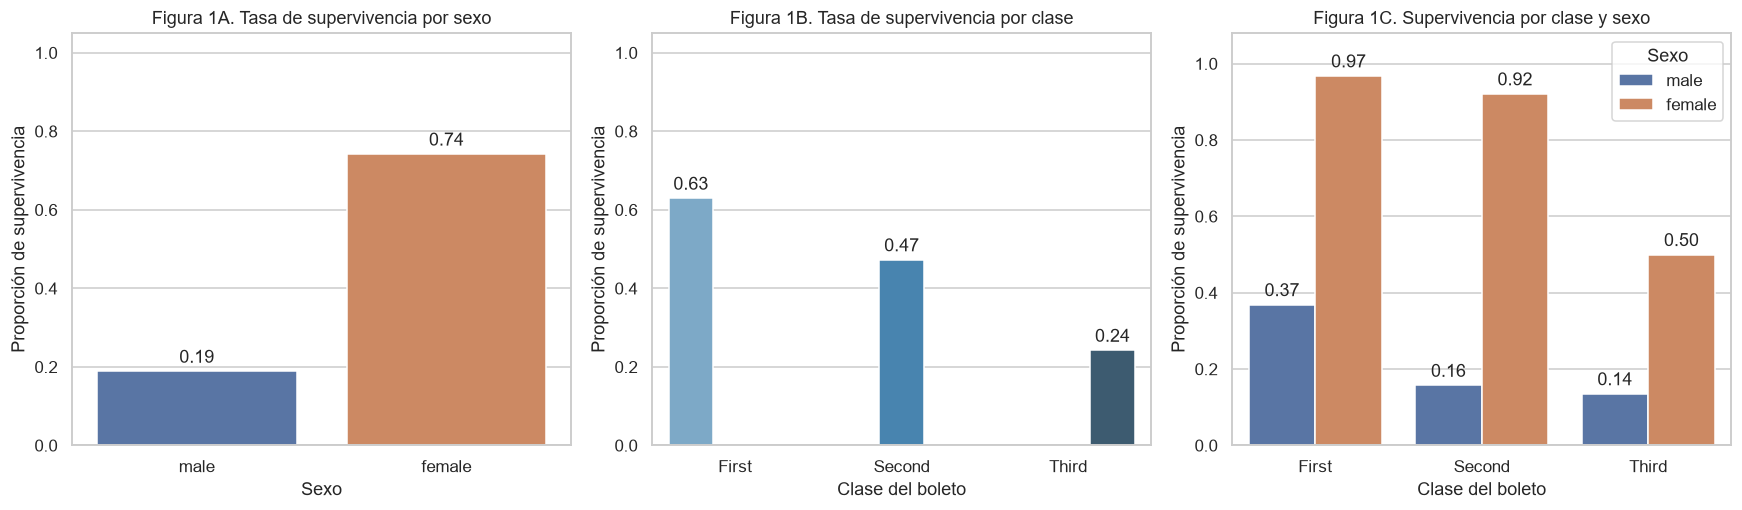

In [2]:
# ==================================================
# ANÁLISIS 1: SUPERVIVENCIA SEGÚN SEXO Y CLASE
# ==================================================

# 1. Resumen marginal por sexo
resumen_sexo = titanic_eda.groupby("sex", observed=False)["survived"].agg(
    Total_pasajeros="count",
    Sobrevivientes="sum",
    Tasa_supervivencia=lambda s: round(s.mean() * 100, 2)
)
print("Tabla 1A. Supervivencia marginal según sexo:")
display(resumen_sexo)

# 2. Resumen marginal por clase
resumen_clase = titanic_eda.groupby("class", observed=False)["survived"].agg(
    Total_pasajeros="count",
    Sobrevivientes="sum",
    Tasa_supervivencia=lambda s: round(s.mean() * 100, 2)
)
print("\nTabla 1B. Supervivencia marginal según clase:")
display(resumen_clase)

# 3. Tabla cruzada: Tasa de supervivencia (%) y tamaño muestral (n) por Clase y Sexo
tasa_cruzada = pd.pivot_table(
    titanic_eda, index="class", columns="sex", values="survived", aggfunc="mean", observed=False
) * 100

conteo_cruzado = pd.pivot_table(
    titanic_eda, index="class", columns="sex", values="survived", aggfunc="count", observed=False
)

print("\nTabla 1C. Tasa de supervivencia (%) por Clase y Sexo:")
display(tasa_cruzada.round(2))

print("\nTabla 1D. Cantidad de pasajeros (n) por Clase y Sexo:")
display(conteo_cruzado)

# 4. Visualización bivariada y multivariada
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel A: Supervivencia por Sexo
sns.barplot(
    data=titanic_eda, x="sex", y="survived", errorbar=None,
    palette=["#4C72B0", "#DD8452"], hue="sex", legend=False, ax=axes[0]
)
axes[0].set_title("Figura 1A. Tasa de supervivencia por sexo")
axes[0].set_xlabel("Sexo")
axes[0].set_ylabel("Proporción de supervivencia")
axes[0].set_ylim(0, 1.05)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2f", padding=3)

# Panel B: Supervivencia por Clase
sns.barplot(
    data=titanic_eda, x="class", y="survived", errorbar=None,
    palette="Blues_d", hue="class", legend=False, ax=axes[1]
)
axes[1].set_title("Figura 1B. Tasa de supervivencia por clase")
axes[1].set_xlabel("Clase del boleto")
axes[1].set_ylabel("Proporción de supervivencia")
axes[1].set_ylim(0, 1.05)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f", padding=3)

# Panel C: Interacción Clase x Sexo
sns.barplot(
    data=titanic_eda, x="class", y="survived", hue="sex", errorbar=None,
    palette=["#4C72B0", "#DD8452"], ax=axes[2]
)
axes[2].set_title("Figura 1C. Supervivencia por clase y sexo")
axes[2].set_xlabel("Clase del boleto")
axes[2].set_ylabel("Proporción de supervivencia")
axes[2].set_ylim(0, 1.08)
axes[2].legend(title="Sexo")
for container in axes[2].containers:
    axes[2].bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

### Interpretación de resultados (Sexo y Clase)
- **Brecha marcada por sexo:** Mientras el **74,20 %** de las mujeres ($233/314$) sobrevivió, solo el **18,89 %** de los hombres ($109/577$) lo hizo. La probabilidad empírica de supervivencia femenina casi cuadruplica la masculina, consistente con la prioridad de evacuación (*"mujeres y niños primero"*).
- **Gradiente socioeconómico por clase:** La supervivencia disminuye monótonamente al descender de clase: **62,96 %** en Primera Clase ($136/216$), **47,28 %** en Segunda Clase ($87/184$) y **24,24 %** en Tercera Clase ($119/491$).
- **Efecto combinado (`class × sex`):** La interacción revela una fuerte estratificación. Las mujeres de Primera y Segunda Clase alcanzaron tasas de supervivencia superiores al **92 %** (**96,81 %** en Primera y **92,11 %** en Segunda), mientras que las mujeres de Tercera Clase redujeron su supervivencia exactamente a la mitad (**50,00 %**, $72/144$). En los hombres, la tasa cayó desde **36,89 %** en Primera Clase hasta **15,74 %** en Segunda y **13,54 %** en Tercera Clase.
- **Decisión exploratoria:** Tanto `sex` como `class` (y su término de interacción) son variables explicativas críticas para cualquier etapa posterior de modelamiento.

---

## 4. Análisis Bivariado 2: Supervivencia según edad

### Pregunta exploratoria
**P4a:** *¿Existen diferencias en la distribución de la edad (`age`) entre sobrevivientes y no sobrevivientes, y qué grupos etarios presentaron mayores tasas de supervivencia?*

### Acción
Sobre los $n = 714$ registros con información válida de edad, se comparan las estadísticas descriptivas (media, mediana, rango intercuartílico) entre `survived = 0` y `survived = 1`, se calculan las tasas de supervivencia por tramo etario (`age_group`) y se visualizan mediante diagramas de caja/violín, curvas de densidad superpuestas (KDE) y barras por grupo etario.

Registros válidos para análisis de edad: 714 de 891 (80.13 %)

Tabla 2A. Estadísticas de edad según supervivencia:


,n,Media,DE,Mediana,Q25,Q75,Min,Max
No sobrevivió (0),424,30.63,14.17,28.0,21.0,39.0,1.00,74.0
Sobrevivió (1),290,28.34,14.95,28.0,19.0,36.0,0.42,80.0



Tabla 2B. Supervivencia por grupo etario:


,Pasajeros_n,Sobrevivientes,Tasa_supervivencia
age_group,,,
Niños (0-12),69,40,57.97
Adolescentes (13-18),70,30,42.86
Adultos jóvenes (19-35),358,137,38.27
Adultos (36-60),195,78,40.00
Adultos mayores (60+),22,5,22.73


C:\Users\rodri\AppData\Local\Temp\ipykernel_12336\299621609.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["No sobrevivió (0)", "Sobrevivió (1)"])


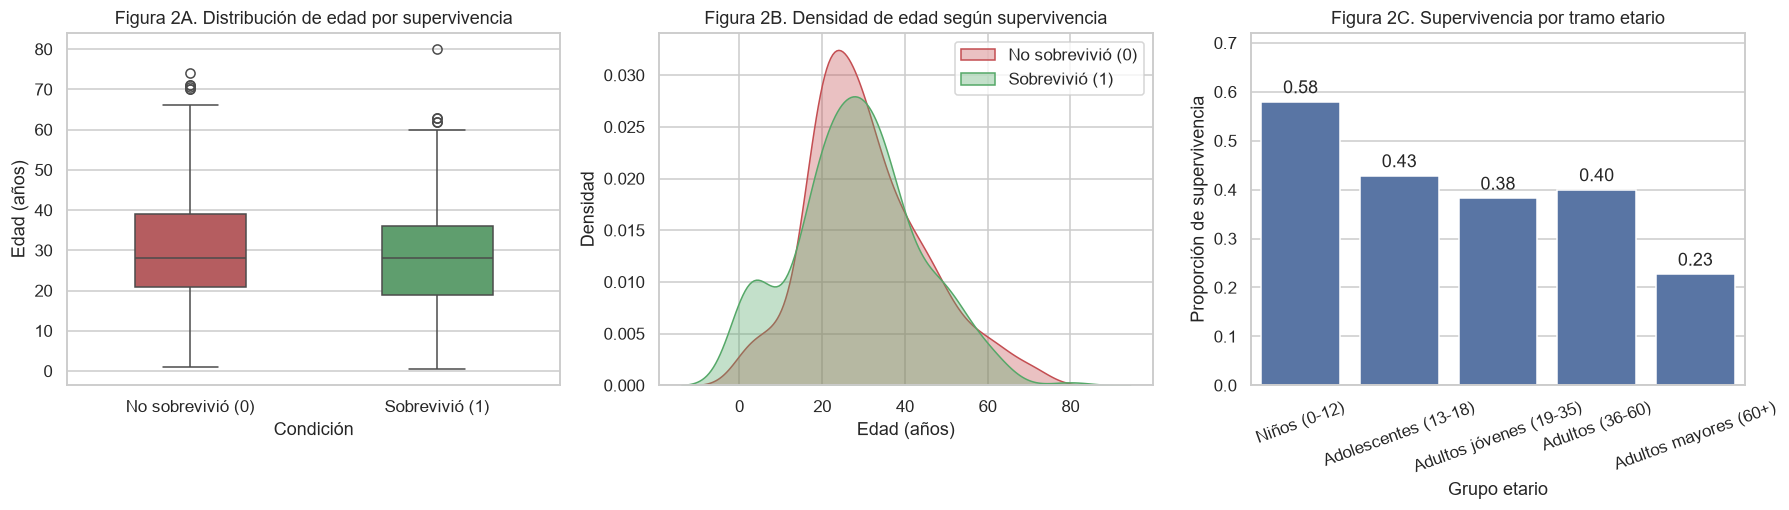

In [3]:
# ==================================================
# ANÁLISIS 2: SUPERVIVENCIA SEGÚN EDAD
# ==================================================

df_edad_valida = titanic_eda.dropna(subset=["age"]).copy()
print(f"Registros válidos para análisis de edad: {len(df_edad_valida)} de {len(titanic_eda)} ({len(df_edad_valida)/len(titanic_eda)*100:.2f} %)")

# 1. Estadísticas descriptivas de edad por condición de supervivencia
desc_edad_surv = df_edad_valida.groupby("survived")["age"].agg(
    n="count",
    Media=lambda s: round(s.mean(), 2),
    DE=lambda s: round(s.std(), 2),
    Mediana=lambda s: round(s.median(), 2),
    Q25=lambda s: round(s.quantile(0.25), 2),
    Q75=lambda s: round(s.quantile(0.75), 2),
    Min="min",
    Max="max"
)
desc_edad_surv.index = ["No sobrevivió (0)", "Sobrevivió (1)"]
print("\nTabla 2A. Estadísticas de edad según supervivencia:")
display(desc_edad_surv)

# 2. Tasa de supervivencia por tramo etario
resumen_tramos_edad = df_edad_valida.groupby("age_group", observed=False)["survived"].agg(
    Pasajeros_n="count",
    Sobrevivientes="sum",
    Tasa_supervivencia=lambda s: round(s.mean() * 100, 2)
)
print("\nTabla 2B. Supervivencia por grupo etario:")
display(resumen_tramos_edad)

# 3. Visualización
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# Panel A: Boxplot + Stripplot de edad por supervivencia
sns.boxplot(
    data=df_edad_valida, x="survived", y="age",
    palette=["#C44E52", "#55A868"], hue="survived", legend=False, width=0.45, ax=axes[0]
)
axes[0].set_title("Figura 2A. Distribución de edad por supervivencia")
axes[0].set_xticklabels(["No sobrevivió (0)", "Sobrevivió (1)"])
axes[0].set_xlabel("Condición")
axes[0].set_ylabel("Edad (años)")

# Panel B: Densidad KDE superpuesta
sns.kdeplot(
    data=df_edad_valida[df_edad_valida["survived"] == 0], x="age",
    fill=True, common_norm=False, color="#C44E52", alpha=0.35, label="No sobrevivió (0)", ax=axes[1]
)
sns.kdeplot(
    data=df_edad_valida[df_edad_valida["survived"] == 1], x="age",
    fill=True, common_norm=False, color="#55A868", alpha=0.35, label="Sobrevivió (1)", ax=axes[1]
)
axes[1].set_title("Figura 2B. Densidad de edad según supervivencia")
axes[1].set_xlabel("Edad (años)")
axes[1].set_ylabel("Densidad")
axes[1].legend()

# Panel C: Tasa de supervivencia por tramo etario
sns.barplot(
    data=df_edad_valida, x="age_group", y="survived", errorbar=None,
    color="#4C72B0", ax=axes[2]
)
axes[2].set_title("Figura 2C. Supervivencia por tramo etario")
axes[2].set_xlabel("Grupo etario")
axes[2].set_ylabel("Proporción de supervivencia")
axes[2].set_ylim(0, 0.72)
axes[2].tick_params(axis="x", rotation=20)
for container in axes[2].containers:
    axes[2].bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

### Interpretación de resultados (Edad)
- **Similitud en medidas centrales globales:** Al comparar globalmente ambos grupos, las medianas de edad son idénticas (**28,00 años** en sobrevivientes y no sobrevivientes) y las medias son muy cercanas (**28,34 años** vs **30,63 años**). Un análisis puramente lineal o basado solo en promedios ocultaría el patrón real.
- **Patrón no lineal visible en colas y tramos:** La curva de densidad (Figura 2B) y la agrupación por tramos (Tabla 2B y Figura 2C) muestran un comportamiento diferenciado en los extremos:
  - **Niños (0 a 12 años):** Presentan la mayor tasa de supervivencia (**57,97 %**, $40/69$), evidenciando un pico marcado en el extremo izquierdo de la distribución de sobrevivientes.
  - **Adultos jóvenes y medios (19 a 60 años):** Mantienen tasas estables en torno al **38,27 % – 40,00 %**.
  - **Adultos mayores (60+ años):** Registran la tasa más baja (**22,73 %**, $5/22$), aunque debe interpretarse con cautela por el tamaño reducido de este subgrupo ($n = 22$).
- **Decisión exploratoria:** Dado el comportamiento no lineal de la edad (protección infantil y menor supervivencia en adultos mayores), conviene conservar tanto la variable continua como una discretización por tramos etarios (o evaluar interacción con `sex`), además de analizar si los 177 nulos de `age` se concentran en alguna clase antes de imputar.

---

## 5. Análisis Bivariado 3: Supervivencia según tamaño del grupo familiar

### Pregunta exploratoria
**P4b:** *¿Cómo varía la tasa de supervivencia según el tamaño del grupo familiar a bordo (`family_size = sibsp + parch + 1`)? ¿Favorece viajar solo, en núcleos pequeños o en familias numerosas?*

### Acción
Se tabula la frecuencia de pasajeros y la proporción de supervivencia para cada valor exacto de `family_size` (de 1 a 11 integrantes) y para la agrupación categórica `family_group` (*Solo*, *Familia pequeña 2-4*, *Familia numerosa 5+*), acompañando los resultados con visualizaciones comparativas.

Tabla 3A. Supervivencia según tamaño exacto del grupo familiar (family_size):


,Pasajeros_n,Sobrevivientes,Tasa_supervivencia
family_size,,,
1,537,163,30.35
2,161,89,55.28
3,102,59,57.84
4,29,21,72.41
5,15,3,20.00
6,22,3,13.64
7,12,4,33.33
8,6,0,0.00
11,7,0,0.00



Tabla 3B. Supervivencia por categoría de grupo familiar:


,Pasajeros_n,Porcentaje_muestra,Sobrevivientes,Tasa_supervivencia
family_group,,,,
Solo (1),537,60.27,163,30.35
Familia pequeña (2-4),292,32.77,169,57.88
Familia numerosa (5+),62,6.96,10,16.13


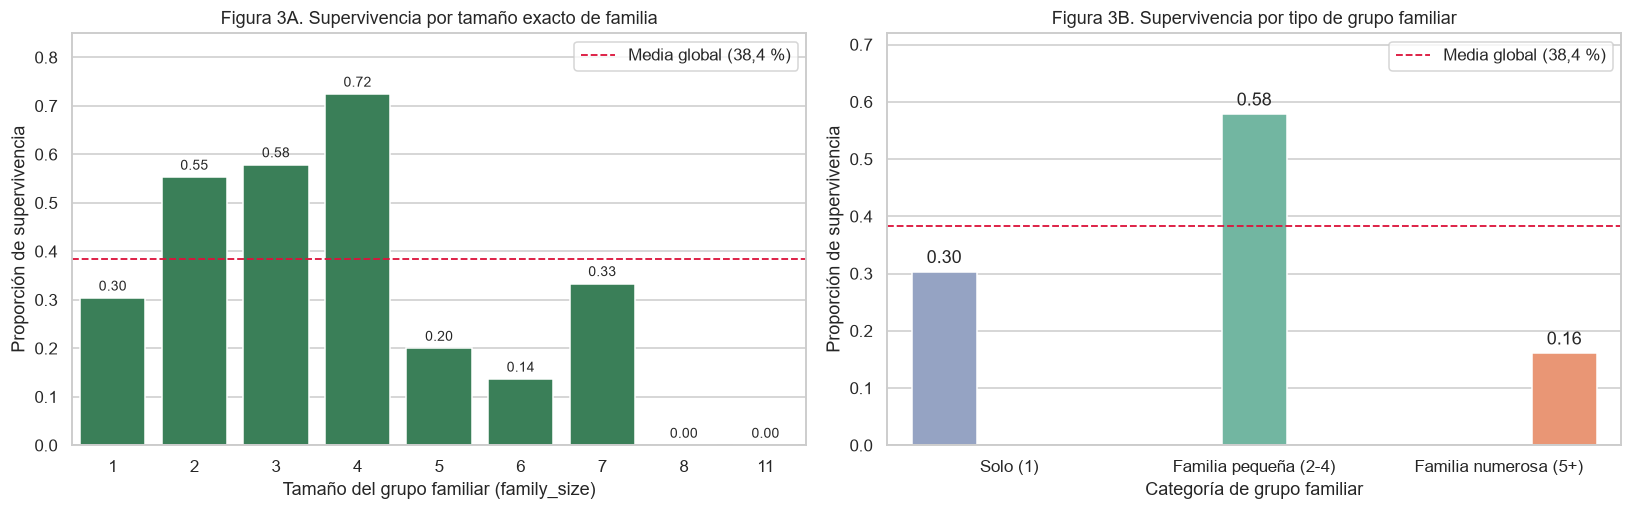

In [4]:
# ==================================================
# ANÁLISIS 3: SUPERVIVENCIA SEGÚN TAMAÑO DE FAMILIA
# ==================================================

# 1. Desglose por tamaño exacto de family_size
resumen_fam_exacto = titanic_eda.groupby("family_size")["survived"].agg(
    Pasajeros_n="count",
    Sobrevivientes="sum",
    Tasa_supervivencia=lambda s: round(s.mean() * 100, 2)
)
print("Tabla 3A. Supervivencia según tamaño exacto del grupo familiar (family_size):")
display(resumen_fam_exacto)

# 2. Desglose por categoría de grupo familiar
resumen_fam_cat = titanic_eda.groupby("family_group", observed=False)["survived"].agg(
    Pasajeros_n="count",
    Porcentaje_muestra=lambda s: round(len(s) / len(titanic_eda) * 100, 2),
    Sobrevivientes="sum",
    Tasa_supervivencia=lambda s: round(s.mean() * 100, 2)
)
print("\nTabla 3B. Supervivencia por categoría de grupo familiar:")
display(resumen_fam_cat)

# 3. Visualización
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# Panel A: Tasa de supervivencia por cada tamaño exacto
sns.barplot(
    data=titanic_eda, x="family_size", y="survived", errorbar=None,
    color="#2E8B57", ax=axes[0]
)
axes[0].axhline(titanic_eda["survived"].mean(), color="crimson", linestyle="--", linewidth=1.2, label="Media global (38,4 %)")
axes[0].set_title("Figura 3A. Supervivencia por tamaño exacto de familia")
axes[0].set_xlabel("Tamaño del grupo familiar (family_size)")
axes[0].set_ylabel("Proporción de supervivencia")
axes[0].set_ylim(0, 0.85)
axes[0].legend()
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2f", padding=3, fontsize=9)

# Panel B: Tasa de supervivencia por tramo familiar
sns.barplot(
    data=titanic_eda, x="family_group", y="survived", errorbar=None,
    palette=["#8DA0CB", "#66C2A5", "#FC8D62"], hue="family_group", legend=False, ax=axes[1]
)
axes[1].axhline(titanic_eda["survived"].mean(), color="crimson", linestyle="--", linewidth=1.2, label="Media global (38,4 %)")
axes[1].set_title("Figura 3B. Supervivencia por tipo de grupo familiar")
axes[1].set_xlabel("Categoría de grupo familiar")
axes[1].set_ylabel("Proporción de supervivencia")
axes[1].set_ylim(0, 0.72)
axes[1].legend()
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

### Interpretación de resultados (Tamaño del grupo familiar)
- **Relación claramente no lineal (forma de U invertida):** La variable `family_size` muestra tres regímenes bien diferenciados:
  1. **Pasajeros que viajaban solos (`family_size = 1`):** Representan el **60,27 %** de la muestra ($537/891$) y presentan una tasa de supervivencia de **30,35 %**, por debajo del promedio general del barco (38,38 %). Este grupo está fuertemente compuesto por hombres adultos en Tercera Clase.
  2. **Familias pequeñas (`family_size` de 2 a 4):** Agrupan al **32,77 %** de los pasajeros ($292/891$) y alcanzan la mayor tasa de supervivencia: **57,88 %** en conjunto (**55,28 %** para tamaño 2; **57,84 %** para tamaño 3; **72,41 %** para tamaño 4).
  3. **Familias numerosas (`family_size >= 5`):** Constituyen el **6,96 %** de los pasajeros ($62/891$) y sufren una caída drástica en su supervivencia hasta **16,13 %** (0 % en familias de 8 y 11 integrantes). Estas familias pertenecían mayoritariamente a Tercera Clase, donde la coordinación del grupo completo durante la evacuación y el acceso a cubiertas superiores resultaron más complejos.
- **Precaución muestral y decisión:** Los conteos individuales para tamaños $\ge 5$ son pequeños ($n$ entre 6 y 22), por lo que agrupar `family_size` en los tramos *Solo (1)*, *Familia pequeña (2-4)* y *Familia numerosa (5+)* estabiliza la estimación y mejora su utilidad analítica.

---

## 6. Análisis Bivariado 4: Comparación de tarifas según clase

### Pregunta exploratoria
**P4c:** *¿Cómo se distribuye la tarifa pagada (`fare`) entre las distintas clases de boleto (`class`), qué magnitud tienen las asimetrías o valores extremos dentro de cada clase, y se asocia la tarifa con la supervivencia?*

### Acción
Se calculan estadísticas de tendencia central y dispersión robusta (media, desviación estándar, mediana, IQR, mínimo y máximo) de `fare` por `class`, se inspeccionan los registros con tarifa igual a cero (`fare == 0`) y valores extremos máximos, y se visualiza la distribución mediante boxplots en escala normal y logarítmica (`log1p`), además de comparar `fare` según supervivencia dentro de cada clase.

Tabla 4A. Estadísticas descriptivas de tarifa (fare) por clase:


,n,Media,DE,Mediana,Q25,Q75,IQR,Min,Max
class,,,,,,,,,
First,216,84.15,78.38,60.29,30.92,93.5,62.58,0.0,512.33
Second,184,20.66,13.42,14.25,13.00,26.0,13.00,0.0,73.50
Third,491,13.68,11.78,8.05,7.75,15.5,7.75,0.0,69.55



Pasajeros con fare == 0: 15 registros (distribución por clase: {'Second': 6, 'First': 5, 'Third': 4})

Tabla 4B. Mediana de tarifa por clase y supervivencia:


,Mediana_fare_NoSobrevivio,Mediana_fare_Sobrevivio
class,,
First,44.75,77.96
Second,13.00,21.00
Third,8.05,8.52


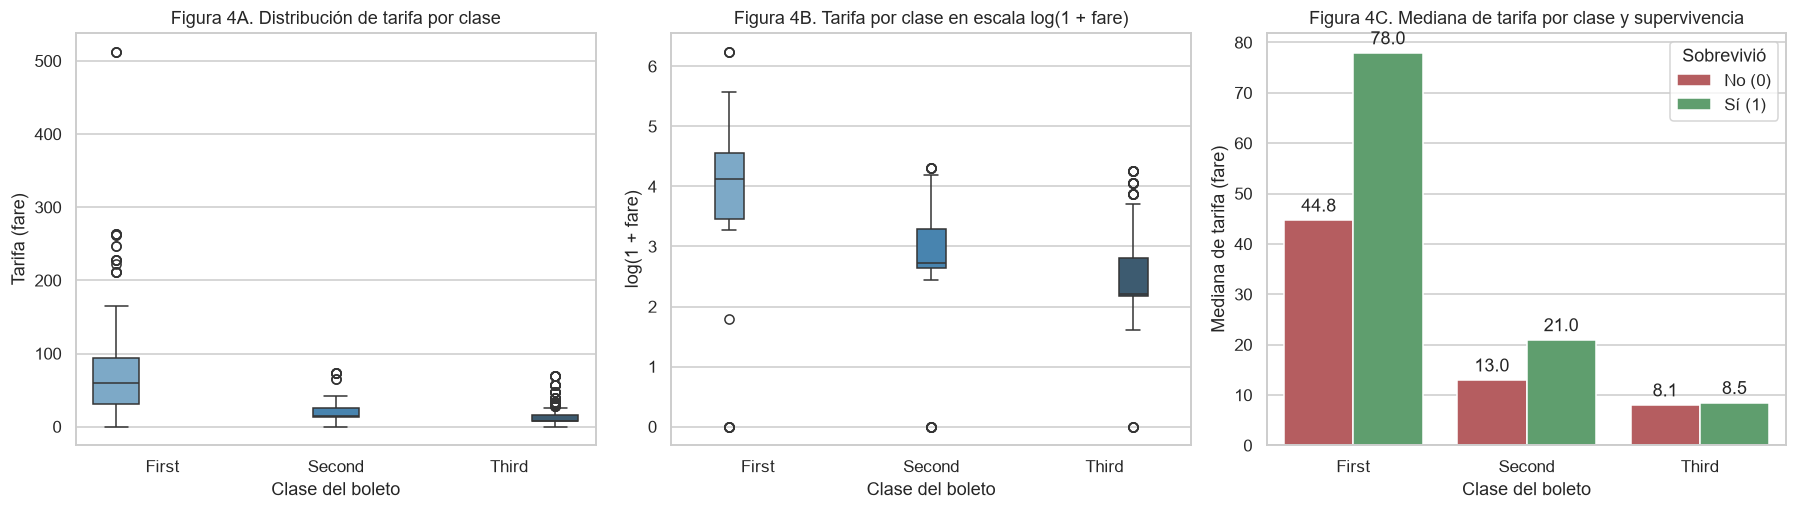

In [5]:
# ==================================================
# ANÁLISIS 4: COMPARACIÓN DE TARIFAS SEGÚN CLASE
# ==================================================

# 1. Estadísticas descriptivas de fare por clase
resumen_tarifa_clase = titanic_eda.groupby("class", observed=False)["fare"].agg(
    n="count",
    Media=lambda s: round(s.mean(), 2),
    DE=lambda s: round(s.std(), 2),
    Mediana=lambda s: round(s.median(), 2),
    Q25=lambda s: round(s.quantile(0.25), 2),
    Q75=lambda s: round(s.quantile(0.75), 2),
    IQR=lambda s: round(s.quantile(0.75) - s.quantile(0.25), 2),
    Min="min",
    Max=lambda s: round(s.max(), 2)
)
print("Tabla 4A. Estadísticas descriptivas de tarifa (fare) por clase:")
display(resumen_tarifa_clase)

# 2. Revisión de casos borde: tarifas = 0 y tarifas máximas
tarifa_cero = titanic_eda[titanic_eda["fare"] == 0]
print(f"\nPasajeros con fare == 0: {len(tarifa_cero)} registros (distribución por clase: {tarifa_cero['class'].value_counts().to_dict()})")

# 3. Mediana de tarifa por clase y condición de supervivencia
tarifa_clase_surv = pd.pivot_table(
    titanic_eda, index="class", columns="survived", values="fare", aggfunc="median", observed=False
).round(2)
tarifa_clase_surv.columns = ["Mediana_fare_NoSobrevivio", "Mediana_fare_Sobrevivio"]
print("\nTabla 4B. Mediana de tarifa por clase y supervivencia:")
display(tarifa_clase_surv)

# 4. Visualización
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# Panel A: Boxplot estándar de fare por clase
sns.boxplot(
    data=titanic_eda, x="class", y="fare",
    palette="Blues_d", hue="class", legend=False, ax=axes[0]
)
axes[0].set_title("Figura 4A. Distribución de tarifa por clase")
axes[0].set_xlabel("Clase del boleto")
axes[0].set_ylabel("Tarifa (fare)")

# Panel B: Boxplot + Stripplot en escala logarítmica para apreciar solapamientos
titanic_eda["log_fare"] = np.log1p(titanic_eda["fare"])
sns.boxplot(
    data=titanic_eda, x="class", y="log_fare",
    palette="Blues_d", hue="class", legend=False, width=0.5, ax=axes[1]
)
axes[1].set_title("Figura 4B. Tarifa por clase en escala log(1 + fare)")
axes[1].set_xlabel("Clase del boleto")
axes[1].set_ylabel("log(1 + fare)")

# Panel C: Mediana de tarifa según clase y supervivencia
sns.barplot(
    data=titanic_eda, x="class", y="fare", hue="survived",
    estimator=np.median, errorbar=None, palette=["#C44E52", "#55A868"], ax=axes[2]
)
axes[2].set_title("Figura 4C. Mediana de tarifa por clase y supervivencia")
axes[2].set_xlabel("Clase del boleto")
axes[2].set_ylabel("Mediana de tarifa (fare)")
axes[2].legend(title="Sobrevivió", labels=["No (0)", "Sí (1)"])
for container in axes[2].containers:
    axes[2].bar_label(container, fmt="%.1f", padding=3)

plt.tight_layout()
plt.show()

### Interpretación de resultados (Tarifas según clase)
- **Diferenciación económica pronunciada entre clases:** Las medianas y rangos intercuartílicos (IQR) confirman una jerarquía tarifaria clara:
  - **Primera Clase:** Mediana de **60,29** (IQR = **62,58**; media = **84,15**).
  - **Segunda Clase:** Mediana de **14,25** (IQR = **13,00**; media = **20,66**).
  - **Tercera Clase:** Mediana de **8,05** (IQR = **7,75**; media = **13,68**).
- **Asimetría positiva y valores extremos:** Primera Clase concentra la mayor dispersión y valores extremos superiores (hasta **512,33**), lo que explica la fuerte cola derecha detectada en el análisis univariado. Al aplicar la transformación `log(1 + fare)` (Figura 4B), se observa que los rangos intercuartílicos están bien separados, aunque existen solapamientos parciales entre las colas superiores de Segunda/Tercera Clase y la cola inferior de Primera Clase (en parte porque en el dataset `fare` registra en ocasiones el valor del boleto grupal/familiar).
- **Casos de tarifa cero (`fare = 0`):** Existen 15 registros con tarifa 0 distribuidos en las tres clases (5 en Primera, 6 en Segunda y 4 en Tercera), correspondientes históricamente a boletos de cortesía, empleados de la compañía o tripulación auxiliar embarcada como pasajero.
- **Relación conjunta `fare × class × survived` (Figura 4C):** Incluso dentro de una misma clase —especialmente en Primera Clase—, quienes sobrevivieron pagaron medianas de tarifa más altas (**77,96** vs **49,50** en Primera Clase), lo que sugiere que `fare` aporta información adicional sobre ubicación de camarotes o poder adquisitivo más allá de la categoría discreta `class`.

---

## 7. Síntesis de Principales Hallazgos, Limitaciones y Conclusiones

### Principales hallazgos del análisis bivariado
1. **Jerarquía de factores asociados a la supervivencia:** El **sexo** y la **clase socioeconómica** emergen como las variables con mayor capacidad discriminante en el dataset. Las mujeres presentaron una tasa de supervivencia del **74,20 %** frente al **18,89 %** de los hombres, mientras que Primera Clase alcanzó un **62,96 %** frente al **24,24 %** de Tercera Clase. El cruce de ambas variables muestra extremos contundentes: **96,81 %** de supervivencia en mujeres de Primera Clase contra **13,54 %** en hombres de Tercera Clase.
2. **Efecto protector infantil y no linealidad de la edad:** Aunque la mediana de edad es idéntica entre sobrevivientes y no sobrevivientes (28 años), el análisis por tramos demuestra que los niños de **0 a 12 años** tuvieron una supervivencia significativamente superior (**57,97 %**), mientras que los adultos mayores de **60 años** registraron la tasa más baja (**22,73 %**).
3. **Dinámica no lineal del grupo familiar (`family_size`):** Viajar en familias pequeñas de **2 a 4 integrantes** se asoció con una tasa de supervivencia de **57,88 %**, casi duplicando la de quienes viajaban solos (**30,35 %**) y más que triplicando la de familias numerosas de **5 o más integrantes** (**16,13 %**).
4. **Estructura tarifaria y colinealidad parcial con `class`:** La variable `fare` discrimina claramente entre clases (medianas de 60,29; 14,25 y 8,05 para Primera, Segunda y Tercera Clase, respectivamente), pero presenta fuerte asimetría positiva, outliers altos en Primera Clase y 15 registros con valor 0.

### Limitaciones y consideraciones metodológicas para la siguiente fase
- **Carácter exploratorio y no causal:** Las asociaciones documentadas describen patrones históricos en los 891 registros disponibles y no deben interpretarse como relaciones causales.
- **Sesgo por datos faltantes en `age`:** El 19,87 % de los pasajeros carece de dato de edad; antes de pasar a una fase inferencial o de modelamiento, debe verificarse si la ausencia de `age` se concentra en Tercera Clase para definir una estrategia de imputación condicionada (por ejemplo, mediana por `class` y `sex`).
- **Tamaños muestrales reducidos en subgrupos extremos:** Categorías como `family_size >= 5` ($n = 62$) o `age > 60` ($n = 22$) presentan baja frecuencia absoluta, por lo que sus tasas porcentuales tienen mayor variabilidad muestral.
- **Preparación para modelamiento (Fase 2):** Se recomienda conservar `sex`, `class`, las variables derivadas `family_group` y `age_group` (o `age` imputada), y evaluar `log1p(fare)` para mitigar la asimetría de la tarifa.